<img src="../../Fink_PrimaryLogo_WEB.jpg" width=400 />

# Use case: Manipulating outputs from the Data Transfer Service

The [Fink data transfer service](https://lsst.fink-portal.org/download) was developed due to the need to transfer large quantities of data for statistical and population studies, as well as to enable training of machine learning models (see [Fraga *et al*, 2024](https://www.aanda.org/articles/aa/full_html/2024/12/aa50370-24/aa50370-24.html)). 

The service has been extensively used during its operation with ZTF data. 

For LSST, we continue to provide the community with easy access to large volumes of data, however, the post-processing of the results requires some fine tunning, given the complexity of the survey. 

You can discover details on how to fetch data from Fink in the documentation. 

In this notebook, we provide you with a few examples on how to manipulate the resulting parquet files. 

## Environment set up

In order to run this notebook, you will need to install the [fink-client](https://github.com/astrolabsoftware/fink-client) and [pyarrow](https://pypi.org/project/pyarrow/). 

Then you can import the following libraries

In [1]:
import numpy as np
import glob
import matplotlib.pylab as plt
import matplotlib
import pyarrow.parquet as pq
import pandas as pd

from fink_client.visualisation import extract_field 
from fink_client.visualisation import show_stamps

# For plots
font = {
    'weight': 'bold',
    'size': 16
}

matplotlib.rc('font', **font)

### Case 1: Reading the data

Suppose that the result of your query to the data transfer service is store in a directory named ... 

In [2]:
topicname = "ftransfer_lsst_2026-11-03_799186"

In [3]:
# Example using pyarrow Table
schema = pq.read_schema(f"../data/arrow_schema_{topicname}.metadata")
table = pq.read_table('../data/' + topicname, schema=schema)

You could easily get a pandas dataframe for convenience, although beware of cast for `diaObjectId` (see https://doc.lsst.fink-broker.org/services/data_transfer/#diaobjectid-casting-errors)

In [4]:
# Make a list of dict for easier manipulation
alerts = table.to_pylist()

In [17]:
len(alerts)

16

In [45]:
# check ids
for i in range(len(alerts)):
    objids = np.unique(extract_field(alerts[i], 'diaObjectId', current='diaSource', previous='prvDiaSources'))
    print(objids)

[313761043604045880]
[313761043604045880]
[313673107053215773]
[313761043604045880]
[313673107053215773]
[313761043604045880]
[313761043604045880]
[313761043604045880]
[313673107053215773]
[313673107053215773]
[313673107053215773]
[313761043604045880]
[313673107053215773]
[313761043604045880]
[313761043604045880]
[313761043604045880]


### Case 2: accessing alert history

Now that your data is available as dictionaries, you are free to explore the potential of the alert package. Important things to keep in mind:

1.  An alert is one point --> `diaSource`
2.  The alert package contains the previous photometric history of that position --> `prvDiaSources` ...
3.  Starting from the second alert, it also contains 30 days of forced photometry preceeding the first alert --> `prvDiaForcedSources`

You can use any information contained in these fields for the construction of your model or filter.

Let's illustrate this task by separating 1 alert:

In [46]:
# Get one alert
alert = alerts[2]

You can explore the meaning of all fields in the schema page: https://lsst.fink-portal.org/schemas. In order to reconstruct the light curve from this, we will use the function below

Let's use it to gather the entire light curve information in a single data frame

In [47]:
mjds = extract_field(alert, 'midpointMjdTai', current="diaSource", previous="prvDiaSources")  # get observation days (MJD)
psfFlux = extract_field(alert, 'psfFlux', current="diaSource", previous="prvDiaSources")  # get difference fluxes
psfFluxErr = extract_field(alert, 'psfFluxErr', current="diaSource", previous="prvDiaSources")  # get difference flux errors
bands = extract_field(alert, 'band', current="diaSource", previous="prvDiaSources")  # get filter bands


We can now plot the entire photometric history for this source

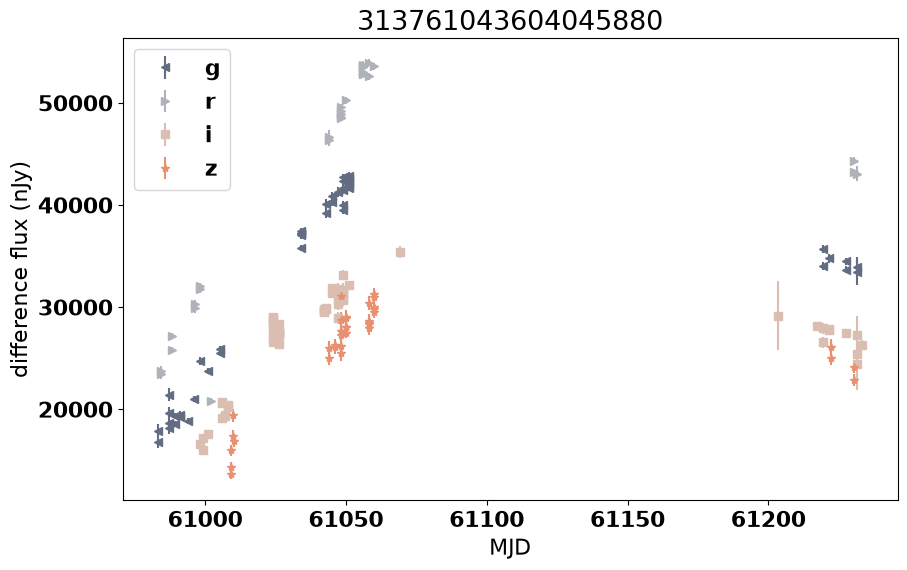

In [48]:
# all lsst bands
all_bands = ['u', 'g', 'r', 'i', 'z', 'y']
symbols = ['o', '<', '>', 's', '*', 'p']
colors = ["#15284f", "#626d84", "#afb2b9", "#dbbeb2", "#e89070", "#f5622e"]

# get unique filters
lc_bands = np.unique(bands)

plt.figure(figsize=(10, 6))
plt.title(objids[0])

for i in range(len(all_bands)):
    if all_bands[i] in lc_bands:
        # identify one filter at a time
        flag = bands == all_bands[i]
        plt.errorbar(mjds[flag], psfFlux[flag], yerr=psfFluxErr[flag], fmt=symbols[i], label=all_bands[i], color=colors[i])

plt.xlabel('MJD')
plt.ylabel('difference flux (nJy)')
plt.legend(loc='upper left')
plt.show()


you can also read with pandas

In [52]:
data_rubin = pd.read_parquet('../data/' + topicname)

Format the data

In [57]:
# get only the columns we need
objid = data_rubin['diaSource'].apply(lambda x: x['diaObjectId'])
flux = data_rubin['diaSource'].apply(lambda x: x['psfFlux'])
fluxerr = data_rubin['diaSource'].apply(lambda x: x['psfFluxErr'])
mjd = data_rubin['diaSource'].apply(lambda x: np.array(x['midpointMjdTai'])) 
band = data_rubin['diaSource'].apply(lambda x: x['band'])
nobs = data_rubin['prvDiaSources'].apply(lambda x: x.shape[0] + 1)
flux_prv = data_rubin['prvDiaSources'].apply(lambda x: np.array([x[i]['psfFlux'] for i in range(len(x))]))
fluxerr_prv = data_rubin['prvDiaSources'].apply(lambda x: np.array([x[i]['psfFluxErr'] for i in range(len(x))]))
mjd_prv = data_rubin['prvDiaSources'].apply(lambda x: np.array([x[i]['midpointMjdTai'] for i in range(len(x))]))
band_prv = flux_hist = data_rubin['prvDiaSources'].apply(lambda x: np.array([x[i]['band'] for i in range(len(x))]))

x_list = []
y_list = []
yerr_list = []
flt_list = []
for k in range(data_rubin.shape[0]):
    # concatenate history and current measurements
    x_list.append(np.array(list(mjd_prv[k]) + [mjd[k]]))
    y_list.append(np.array(list(flux_prv[k]) + [flux[k]]))
    yerr_list.append(np.array(list(fluxerr_prv[k]) + [fluxerr[k]]))
    flt_list.append(np.array(list(band_prv[k]) + [band[k]]))

data_df = pd.DataFrame()
data_df['objid'] = objid
data_df['mjd'] = x_list
data_df['flux'] = y_list
data_df['fluxerr'] = yerr_list
data_df['band'] = flt_list

In [58]:
data_df

,objid,mjd,flux,fluxerr,band
0,313761043604045880,"[61003.336679130254, 61004.30177726407, 61004....","[1007.5594482421875, 2069.40673828125, 2197.39...","[170.8847198486328, 157.63409423828125, 124.95...","[r, r, r, i, z, z, z, z, z, z, g, i, i, z, z, ..."
1,313761043604045880,"[61003.336679130254, 61004.30177726407, 61004....","[1007.5594482421875, 2069.40673828125, 2197.39...","[170.8847198486328, 157.63409423828125, 124.95...","[r, r, r, i, z, z, z, z, z, z, g, i, i, z, z, ..."
2,313673107053215773,"[60983.202726822914, 60983.20361924672, 60984....","[16812.291015625, 17901.390625, 23432.30078125...","[649.7747802734375, 645.759033203125, 524.2481...","[g, g, r, r, g, g, g, g, r, r, g, g, g, g, g, ..."
3,313761043604045880,"[61003.336679130254, 61004.30177726407, 61004....","[1007.5594482421875, 2069.40673828125, 2197.39...","[170.8847198486328, 157.63409423828125, 124.95...","[r, r, r, i, z, z, z, z, z, z, g, i, i, z, z, ..."
4,313673107053215773,"[60983.202726822914, 60983.20361924672, 60984....","[16812.291015625, 17901.390625, 23432.30078125...","[649.7747802734375, 645.759033203125, 524.2481...","[g, g, r, r, g, g, g, g, r, r, g, g, g, g, g, ..."
5,313761043604045880,"[61003.336679130254, 61004.30177726407, 61004....","[1007.5594482421875, 2069.40673828125, 2197.39...","[170.8847198486328, 157.63409423828125, 124.95...","[r, r, r, i, z, z, z, z, z, z, g, i, i, z, z, ..."
6,313761043604045880,"[61003.336679130254, 61004.30177726407, 61004....","[1007.5594482421875, 2069.40673828125, 2197.39...","[170.8847198486328, 157.63409423828125, 124.95...","[r, r, r, i, z, z, z, z, z, z, g, i, i, z, z, ..."
7,313761043604045880,"[61003.336679130254, 61004.30177726407, 61004....","[1007.5594482421875, 2069.40673828125, 2197.39...","[170.8847198486328, 157.63409423828125, 124.95...","[r, r, r, i, z, z, z, z, z, z, g, i, i, z, z, ..."
8,313673107053215773,"[60983.202726822914, 60983.20361924672, 60984....","[16812.291015625, 17901.390625, 23432.30078125...","[649.7747802734375, 645.759033203125, 524.2481...","[g, g, r, r, g, g, g, g, r, r, g, g, g, g, g, ..."
9,313673107053215773,"[60983.202726822914, 60983.20361924672, 60984....","[16812.291015625, 17901.390625, 23432.30078125...","[649.7747802734375, 645.759033203125, 524.2481...","[g, g, r, r, g, g, g, g, r, r, g, g, g, g, g, ..."
